# SO-SIMBA MMS – snow depth on Antarctic sea ice

## Overview

| | |
|---|---|
| **Product** | Merged Multi-Sensor (MMS) snow depth on sea ice from laser (ICESat-2) and radar (CryoSat-2, Sentinel-3A, Sentinel-3B) freeboards |
| **Producers** | Marion Bocquet, Robert Ricker (NORCE Norwegian Research Centre) |
| **Time coverage** | 14 October 2018 – 31 August 2025, daily |
| **Grid** | 25 km EASE2, Southern Hemisphere (EPSG:6932) |
| **DOI** | *to be added* |
| **Data server** | [THREDDS catalogue](https://thredds.met.no/thredds/catalog/arcticdata/SO-SIMBA/SOSIMBA_MMS_SD_vf/catalog.html) (OPeNDAP, HTTP, WMS) |
| **Zarr store** | `https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_MMS_SD_vf.zarr/` |
| **Licence** | CC-BY-4.0 |
| **Project** | ESA Polar Science Cluster, SO-SIMBA |

This notebook reads the data **remotely, without downloading anything**, from the cloud-optimised **zarr** copy
of the product (all days in one dataset):

1. Open the dataset and select one day
2. Maps of the snow depth and its uncertainty, and of the laser and radar freeboards
3. Time series of the mean snow depth over a period

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import pandas as pd
import xarray as xr

# ---- to adapt
DATE = "2022-09-15"   # day to map (Oct 2018 - Aug 2025)

## Data access

The whole record is a single cloud-optimised **zarr** store on the EarthCODE object storage.
`xarray` opens it lazily: only the chunks you use are transferred, so a map or a multi-year time series is read
directly, without looping over files. Requires the `zarr`, `fsspec`, `aiohttp` and `dask` packages
(`pip install zarr fsspec aiohttp dask`).

In [2]:
ZARR = "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_MMS_SD_vf.zarr/"


def open_zarr():
    """Whole record (all days), opened lazily from the zarr store."""
    return xr.open_dataset(ZARR, engine="zarr", chunks={})

## 1. Open the dataset and select one day

In [3]:
ds = open_zarr()                                     # all days, nothing loaded yet
print(f"{ds.sizes['time']} days, {ds.time.values[0]:.10} to {ds.time.values[-1]:.10}")
ds_day = ds.sel(time=DATE, method="nearest")         # one day

# variables, units and description
for v in ds_day.data_vars:
    print(f"{v:40s} {ds_day[v].attrs.get('units', ''):8s} {ds_day[v].attrs.get('long_name', '')}")

2444 days, 2018-10-14 to 2025-08-31
crs                                               
ku_freeboard_interp                      m        ku-band radar freeboard interpolated
ku_freeboard_interp_unc                  m        ku-band radar freeboard uncertainty interpolated
ku_freeboard_raw                         m        ku-band radar freeboard
ku_freeboard_raw_unc                     m        ku-band radar freeboard uncertainty
region                                   1        region identifier
rolling_median_total_freeboard_interp    m        3-day moving window temporal median of gap-filled total freeboard
rolling_std_total_freeboard              m        temporal standard deviation of total freeboard calculated over a 3-day moving window
snow_density                             kg m-3   density of the snow layer
snow_depth                               m        thickness of the snow layer
snow_depth_unc                           m        uncertainty thickness of the snow layer
snow

## 2. Maps

The grid is a Lambert azimuthal equal-area projection centred on the South Pole (EASE2, EPSG:6932);
`xc` and `yc` are in metres.

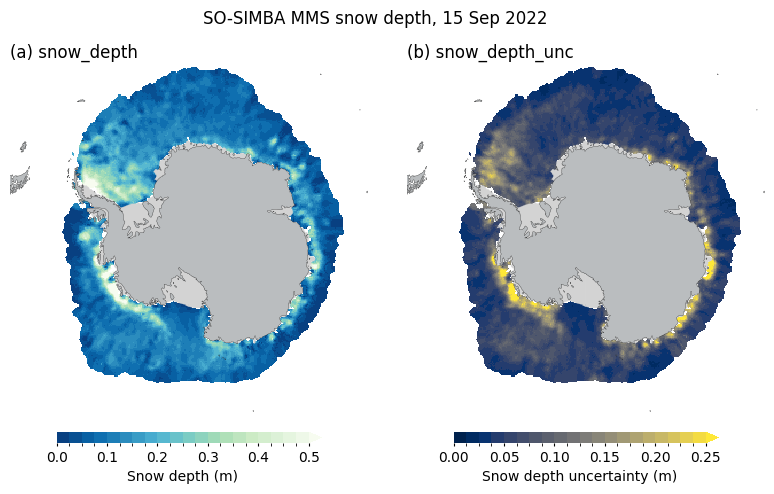

In [8]:
crs = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=-90)
extent = [-3.9e6, 3.9e6, -3.9e6, 3.9e6]   # x0, x1, y0, y1 in metres

land = cfeature.NaturalEarthFeature("physical", "coastline", "50m", facecolor=(0.73, 0.74, 0.75), edgecolor="black")
shelves = cfeature.NaturalEarthFeature("physical", "antarctic_ice_shelves_polys", "50m", facecolor="lightgray",
                                       edgecolor="lightgray")


def plot_map(ax, da, cmap, vmin, vmax, label, n_steps=20):
    """Map of a 2-D field on the EASE2 grid, with n_steps colour levels between vmin and vmax."""
    levels = np.linspace(vmin, vmax, n_steps + 1)
    cmap = plt.get_cmap(cmap, n_steps + 1)                      # + 1 colour for values above vmax
    norm = BoundaryNorm(levels, ncolors=cmap.N, extend="max")
    ax.set_extent(extent, crs=crs)
    im = ax.pcolormesh(da.xc, da.yc, da.squeeze(), cmap=cmap, norm=norm, transform=crs,
                       shading="auto", rasterized=True)
    ax.add_feature(shelves, linewidth=0.2, zorder=2)
    ax.add_feature(land, linewidth=0.2, zorder=3)
    ax.axis("off")
    cb = plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02, aspect=25, extend="max")
    cb.set_label(label)
    cb.set_ticks(levels[::4])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2)
    return im


fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.snow_depth, "GnBu_r", 0, 0.5, "Snow depth (m)")
plot_map(axes[1], ds_day.snow_depth_unc, "cividis", 0, 0.25, "Snow depth uncertainty (m)")
axes[0].set_title("(a) snow_depth", loc="left")
axes[1].set_title("(b) snow_depth_unc", loc="left")
fig.suptitle(f"SO-SIMBA MMS snow depth, {pd.Timestamp(ds_day.time.values):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

Snow depth is derived from the difference between the laser total freeboard and the Ku-band radar freeboard.

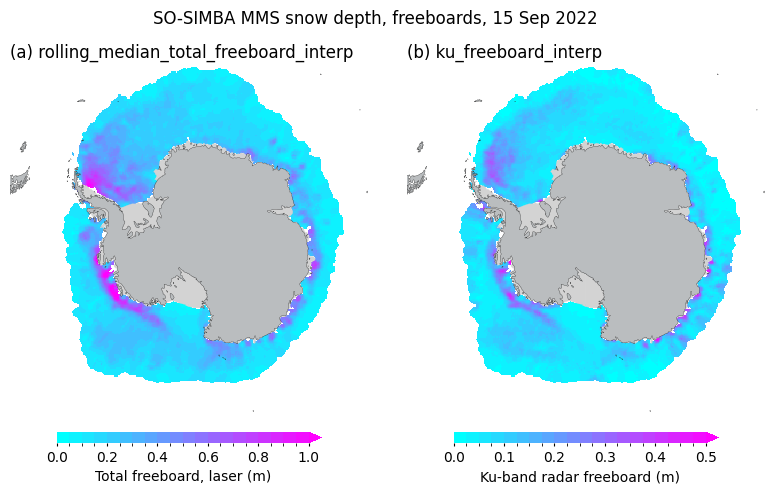

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.rolling_median_total_freeboard_interp, "cool", 0, 1, "Total freeboard, laser (m)")
plot_map(axes[1], ds_day.ku_freeboard_interp, "cool", 0, 0.5, "Ku-band radar freeboard (m)")
axes[0].set_title("(a) rolling_median_total_freeboard_interp", loc="left")
axes[1].set_title("(b) ku_freeboard_interp", loc="left")
fig.suptitle(f"SO-SIMBA MMS snow depth, freeboards, {pd.Timestamp(ds_day.time.values):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

## 3. Time series of the mean snow depth

Mean over all valid grid cells, for every day between `START` and `END`: the period is selected in the store and
averaged in one go.

In [12]:
START, END = "2020-01-01", "2022-12-31"
ds_year = ds.sel(time=slice(START, END))
ts = ds_year.snow_depth.mean(dim=['yc', 'xc'], skipna=True).compute()
ts

<xarray.DataArray 'snow_depth' (time: 1096)> Size: 4kB
array([0.10150897, 0.10232192, 0.10058176, ..., 0.10725631, 0.10844582,
       0.10895556], shape=(1096,), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 9kB 2020-01-01T12:00:00 ... 2022-12-31T12:...
Attributes:
    standard_name:          surface_snow_thickness
    long_name:              thickness of the snow layer
    units:                  m
    grid_mapping:           crs
    comment:                Snow thickness comming from the 3days_rolling_med...
    coverage_content_type:  auxiliaryInformation

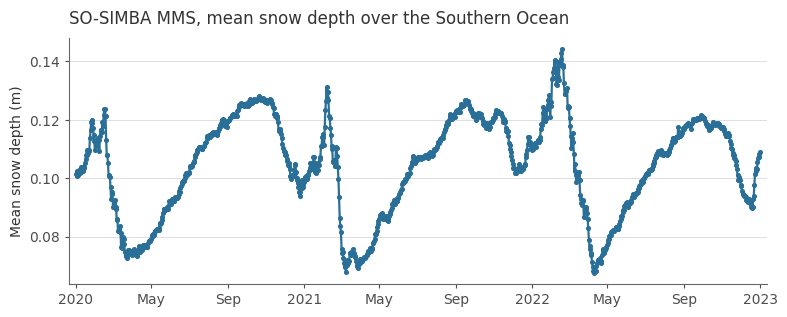

In [13]:
COLOR = "#2a6f97"   # ocean blue
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ts.time, ts.values, color=COLOR, lw=1.6)
ax.scatter(ts.time, ts.values, color=COLOR, s=7, zorder=3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
ax.grid(axis="y", color="0.85", lw=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=10))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_ylabel("Mean snow depth (m)", color="0.2")
ax.set_title("SO-SIMBA MMS, mean snow depth over the Southern Ocean", loc="left", color="0.2", pad=10)
ax.margins(x=0.01)
plt.show()

## References

Bocquet, M. and Ricker, R.: SO-SIMBA Merged Multi Sensor of Snow Depth on Sea Ice (Antarctic sea ice),
Norwegian Meteorological Institute / Arctic Data Centre, DOI to be added.